In [53]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

sns.set_style('darkgrid')
plt.rcParams.update({
    'lines.linewidth': 2,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'axes.labelsize': 14,
    'legend.fontsize': 12,
    'axes.titlesize': 16,
})

In [54]:
train_df = pd.read_csv('/scratch/storage0/ce20b049/Ishita/FineTuning_DDP/Modular/Final/csvs/Exp_No shuffle.csv')

In [55]:
ycols = [col for col in train_df.columns if col.endswith('Exposure')]
print(len(ycols))
print(ycols)

12
['Num=16,No DP - Exposure', 'Num=4,No DP - Exposure', 'Num=1,No DP - Exposure', 'Num=16,epsilon=32 - Exposure', 'Num=4,epsilon=32 - Exposure', 'Num=1,epsilon=32 - Exposure', 'Num=16,epsilon=8 - Exposure', 'Num=16,epsilon=2 - Exposure', 'Num=4,epsilon=8 - Exposure', 'Num=4,epsilon=2 - Exposure', 'Num=1,epsilon=8 - Exposure', 'Num=1,epsilon=2 - Exposure']


In [56]:
xcol = 'Epoch'
print(xcol)

Epoch


In [57]:
def clean_label(label):
    match = re.search(r'Num=\d+.*?(?:epsilon=\d+|No DP)', label)
    if match:
        clean = match.group(0).replace('Num=', 'n=').replace('epsilon', r'$\epsilon$')
        return clean
    else:
        return label.replace('Num=', 'n=')

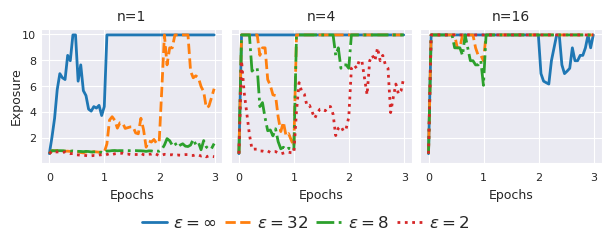

In [ ]:
import matplotlib.pyplot as plt

n_values = ['1', '4', '16']
eps_keys = ['No DP', 'ε=32', 'ε=8', 'ε=2']

epsilon_color_map = {
    'No DP': 'C0',
    'ε=32': 'C1',
    'ε=8': 'C2',
    'ε=2': 'C3',
}

epsilon_style_map = {
    'No DP': '-',
    'ε=32': '--',
    'ε=8': '-.',
    'ε=2': ':'
}

fig, axs = plt.subplots(1, 3, figsize=(6, 2), sharey=True, constrained_layout=True)

for i, n in enumerate(n_values):
    ax = axs[i]
    for eps in eps_keys:
        for label in ycols:
            if f'Num={n},' in label:
                if eps == 'No DP' and 'No DP' in label:
                    ax.plot(train_df[xcol], train_df[label],
                            label=r'$\epsilon = \infty$',
                            color=epsilon_color_map[eps],
                            linestyle=epsilon_style_map[eps],
                            linewidth=2)
                elif eps in label.replace('epsilon=', 'ε='):
                    ax.plot(train_df[xcol], train_df[label],
                            label=eps,
                            color=epsilon_color_map[eps],
                            linestyle=epsilon_style_map[eps],
                            linewidth=2)

    ax.set_title(f'n={n}', fontsize=10)
    ax.set_xlabel('Epochs', fontsize=9)
    ax.set_xticks([0, 1, 2, 3])
    ax.tick_params(labelsize=8)

    if i == 0:
        ax.set_ylabel('Exposure', fontsize=9, labelpad=2)
        ax.yaxis.set_label_coords(-0.1, 0.5)
        ax.tick_params(axis='y', pad=0)
    else:
        ax.tick_params(axis='y', labelleft=False)

eps_latex_map = {
    'No DP': r'$\epsilon = \infty$',
    'ε=32': r'$\epsilon = 32$',
    'ε=8': r'$\epsilon = 8$',
    'ε=2': r'$\epsilon = 2$'
}


from matplotlib.lines import Line2D
legend_lines = [
    Line2D([0], [0], color=epsilon_color_map[eps], linestyle=epsilon_style_map[eps], linewidth=2)
    for eps in eps_keys
]

fig.legend(legend_lines,
           [eps_latex_map[eps] for eps in eps_keys],
           loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.2),
           columnspacing=0.5, handlelength=1.5, handletextpad=0.4, frameon=False)

# plt.tight_layout()
# plt.savefig("pdfs_save/exposure_noshuffle_num.pdf", format="pdf", bbox_inches="tight", dpi=300)
plt.show()

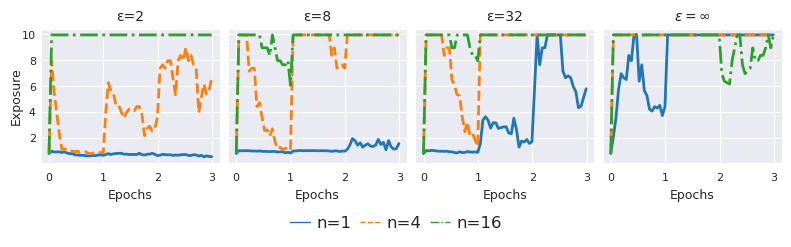

In [ ]:
n_values = ['1', '4', '16']
eps_keys = ['ε=2', 'ε=8', 'ε=32', 'No DP']

n_style_map = {
    '1': {'color': 'C0', 'linestyle': '-'},
    '4': {'color': 'C1', 'linestyle': '--'},
    '16': {'color': 'C2', 'linestyle': '-.'}
}

fig, axs = plt.subplots(1, 4, figsize=(7.8, 2), sharey=True, constrained_layout=True)

for i, eps in enumerate(eps_keys):
    ax = axs[i]
    for n in n_values:
        for label in ycols:
            if f'Num={n},' in label:
                if eps == 'No DP' and 'No DP' in label:
                    ax.plot(train_df[xcol], train_df[label],
                            label=f'n={n}', 
                            color=n_style_map[n]['color'],
                            linestyle=n_style_map[n]['linestyle'],
                            linewidth=2)
                elif eps in label.replace('epsilon=', 'ε='):
                    ax.plot(train_df[xcol], train_df[label],
                            label=f'n={n}', 
                            color=n_style_map[n]['color'],
                            linestyle=n_style_map[n]['linestyle'],
                            linewidth=2)

    title = r'$\epsilon = \infty$' if eps == 'No DP' else eps
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('Epochs', fontsize=9)
    ax.set_xticks([0, 1, 2, 3])
    ax.tick_params(labelsize=8)

    if i == 0:
        ax.set_ylabel('Exposure', fontsize=9, labelpad=2)
        ax.yaxis.set_label_coords(-0.1, 0.5)
        ax.tick_params(axis='y', pad=0)
    else:
        ax.tick_params(axis='y', labelleft=False)

from matplotlib.lines import Line2D
legend_lines = [Line2D([0], [0], color=n_style_map[n]['color'], linestyle=n_style_map[n]['linestyle'], linewidth=1)
                for n in n_values]

fig.legend(legend_lines,
           [f'n={n}' for n in n_values],
           loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.2),
           columnspacing=0.5, handlelength=1.2, handletextpad=0.4, frameon=False)
# plt.tight_layout()
# plt.savefig("pdfs_save/exposure_noshuffle_ep.pdf", format="pdf", bbox_inches="tight", dpi=300)
plt.show()